Matplotlib Session 11 – Exporting & Saving Plots


Exported: tiffin_72.png
DPI: 72
Pixel Shape: (425, 855, 4)
File Size: 24.81 KB

Exported: tiffin_150.png
DPI: 150
Pixel Shape: (884, 1782, 4)
File Size: 62.04 KB

Exported: tiffin_300.png
DPI: 300
Pixel Shape: (1769, 3570, 4)
File Size: 139.93 KB


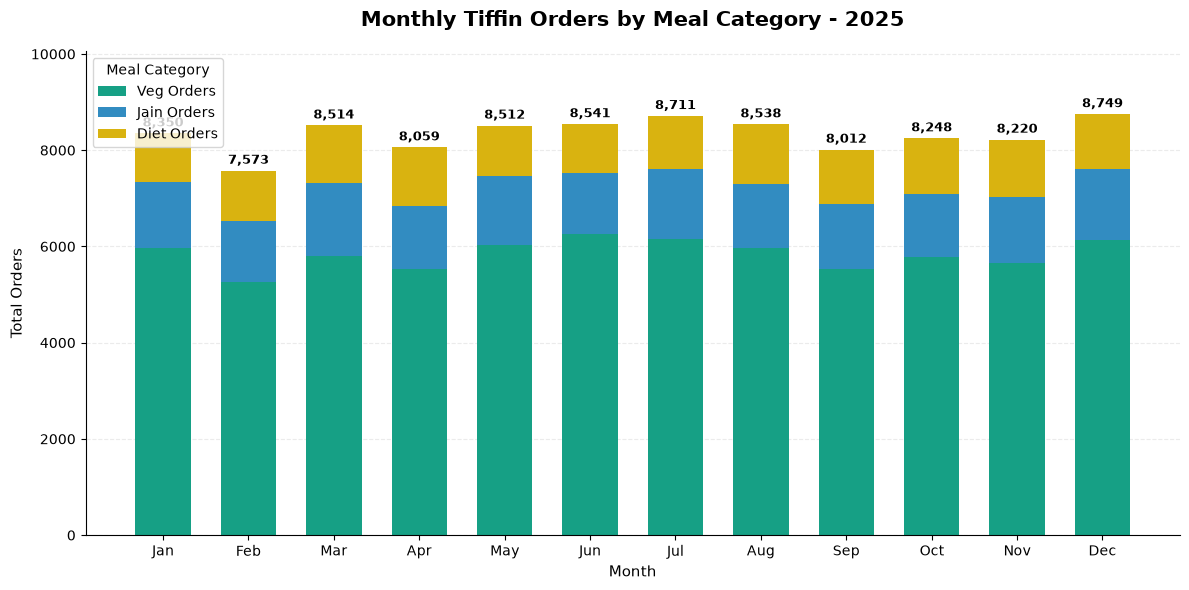


SESSION 11 - TASK 1 COMPLETED SUCCESSFULLY!


In [1]:

# MATPLOTLIB SESSION 11 - TASK 1
# Export Monthly Tiffin Chart at Different DPI Settings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load daily tiffin order dataset
data_file = Path("tiffin_daily.csv")

if not data_file.exists():
    raise FileNotFoundError(
        "tiffin_daily.csv not found. "
        "Place the CSV in your notebook working folder."
    )

df = pd.read_csv(
    data_file,
    parse_dates=["date"]
)

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

# Calculate monthly order totals
monthly_orders = (
    df.set_index("date")[["veg", "jain", "diet"]]
    .resample("MS")
    .sum()
)

# Prepare chart data
months = monthly_orders.index.strftime("%b")

veg_orders = monthly_orders["veg"].to_numpy()
jain_orders = monthly_orders["jain"].to_numpy()
diet_orders = monthly_orders["diet"].to_numpy()

monthly_totals = veg_orders + jain_orders + diet_orders

# Create monthly stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    months,
    veg_orders,
    color="#16A085",
    width=0.65,
    label="Veg Orders"
)

ax.bar(
    months,
    jain_orders,
    bottom=veg_orders,
    color="#328CC1",
    width=0.65,
    label="Jain Orders"
)

ax.bar(
    months,
    diet_orders,
    bottom=veg_orders + jain_orders,
    color="#D9B310",
    width=0.65,
    label="Diet Orders"
)

# Add monthly total labels
for index, total in enumerate(monthly_totals):
    ax.annotate(
        f"{total:,}",
        xy=(index, total),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Professional chart formatting
ax.set_title(
    "Monthly Tiffin Orders by Meal Category - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Total Orders", fontsize=11)

ax.set_ylim(0, monthly_totals.max() * 1.15)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Meal Category",
    loc="upper left"
)

fig.tight_layout()

# Export same chart at three DPI settings
dpi_settings = [72, 150, 300]

for dpi in dpi_settings:

    filename = f"tiffin_{dpi}.png"

    # Save BEFORE plt.show()
    fig.savefig(
        filename,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Read exported image back
    image = plt.imread(filename)

    print(f"\nExported: {filename}")
    print(f"DPI: {dpi}")
    print(f"Pixel Shape: {image.shape}")
    print(
        f"File Size: "
        f"{Path(filename).stat().st_size / 1024:.2f} KB"
    )

# Display chart after saving
plt.show()

print("\nSESSION 11 - TASK 1 COMPLETED SUCCESSFULLY!")


Task 2: Export Charts as SVG and PDF

In [2]:

# MATPLOTLIB SESSION 11 - TASK 2
# Export SVG, PDF and Generate File Size Report

import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Reuse the stacked bar chart figure from Task 1.
# Make sure Task 1 has been executed first.

if "fig" not in globals():
    raise RuntimeError(
        "Run Session 11 Task 1 first to create the chart."
    )

# Export the same chart in vector formats
vector_files = [
    "tiffin_chart.svg",
    "tiffin_chart.pdf"
]

for filename in vector_files:

    fig.savefig(
        filename,
        bbox_inches="tight"
    )

    print(f"Exported successfully: {filename}")

# List all five exported charts
exported_files = [
    "tiffin_72.png",
    "tiffin_150.png",
    "tiffin_300.png",
    "tiffin_chart.svg",
    "tiffin_chart.pdf"
]

# Build professional export report
export_records = []

for filename in exported_files:

    file_path = Path(filename)

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Missing exported file: {filename}"
        )

    file_size_bytes = os.path.getsize(file_path)
    file_size_kb = file_size_bytes / 1024

    export_records.append({
        "file_name": filename,
        "format": file_path.suffix.replace(".", "").upper(),
        "size_kb": round(file_size_kb, 2)
    })

# Convert report into a pandas DataFrame
export_summary = pd.DataFrame(export_records)

# Save report as CSV
report_file = "tiffin_export_sizes.csv"

export_summary.to_csv(
    report_file,
    index=False
)

# Display export report
print("\nTIFFIN CHART EXPORT SIZE REPORT")
print("-" * 50)

print(export_summary.to_string(index=False))

print("\nTotal Exported Charts:", len(export_summary))

print(
    "Total File Size:",
    f"{export_summary['size_kb'].sum():.2f} KB"
)

print("\nReport saved:", report_file)

print("\nSESSION 11 - TASK 2 COMPLETED SUCCESSFULLY!")


Exported successfully: tiffin_chart.svg
Exported successfully: tiffin_chart.pdf

TIFFIN CHART EXPORT SIZE REPORT
--------------------------------------------------
       file_name format  size_kb
   tiffin_72.png    PNG    24.81
  tiffin_150.png    PNG    62.04
  tiffin_300.png    PNG   139.93
tiffin_chart.svg    SVG    64.32
tiffin_chart.pdf    PDF    27.36

Total Exported Charts: 5
Total File Size: 318.46 KB

Report saved: tiffin_export_sizes.csv

SESSION 11 - TASK 2 COMPLETED SUCCESSFULLY!


In [3]:

# SESSION 11 - TASK 3
# Check whether PowerPoint creation is available

import importlib.util

if importlib.util.find_spec("pptx") is not None:
    print("SUCCESS: PowerPoint creation is available!")
else:
    print("python-pptx is not installed.")
    print("We will use a method that requires no installation.")


python-pptx is not installed.
We will use a method that requires no installation.


In [4]:
import importlib.util

if importlib.util.find_spec("pptx") is not None:
    print("SUCCESS: PowerPoint creation is available!")
else:
    print("python-pptx is not installed.")

python-pptx is not installed.


In [5]:

from pathlib import Path

chart_file = Path("tiffin_300.png")

if chart_file.is_file():
    print("SUCCESS: Chart image found!")
    print("File:", chart_file.resolve())
    print("Size:", round(chart_file.stat().st_size / 1024, 2), "KB")
else:
    print("Chart image not found.")
    print("Current folder:", Path.cwd())


SUCCESS: Chart image found!
File: D:\sql+power bi\assmt\recharge_export.ipynb\tiffin_300.png
Size: 139.93 KB


In [6]:

# SESSION 11 - TASK 3
# Create a PowerPoint without installing packages

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from xml.sax.saxutils import escape

# Input and output files
chart = Path("tiffin_300.png")
output = Path("tiffin_chart_slide.pptx")

if not chart.is_file():
    raise FileNotFoundError("tiffin_300.png not found.")

# Slide dimensions: widescreen 16:9
slide_w = 12192000
slide_h = 6858000

title = escape("Tiffin Orders 2025 - Monthly Mix")

content_types = """<?xml version="1.0" encoding="UTF-8"?>
<Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types">
<Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/>
<Default Extension="xml" ContentType="application/xml"/>
<Default Extension="png" ContentType="image/png"/>
<Override PartName="/ppt/presentation.xml" ContentType="application/vnd.openxmlformats-officedocument.presentationml.presentation.main+xml"/>
<Override PartName="/ppt/slides/slide1.xml" ContentType="application/vnd.openxmlformats-officedocument.presentationml.slide+xml"/>
<Override PartName="/ppt/slideMasters/slideMaster1.xml" ContentType="application/vnd.openxmlformats-officedocument.presentationml.slideMaster+xml"/>
<Override PartName="/ppt/slideLayouts/slideLayout1.xml" ContentType="application/vnd.openxmlformats-officedocument.presentationml.slideLayout+xml"/>
</Types>"""

root_rels = """<?xml version="1.0" encoding="UTF-8"?>
<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships">
<Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/officeDocument" Target="ppt/presentation.xml"/>
</Relationships>"""

presentation = f"""<?xml version="1.0" encoding="UTF-8"?>
<p:presentation xmlns:p="http://schemas.openxmlformats.org/presentationml/2006/main"
xmlns:a="http://schemas.openxmlformats.org/drawingml/2006/main"
xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships">
<p:sldMasterIdLst><p:sldMasterId id="2147483648" r:id="rId1"/></p:sldMasterIdLst>
<p:sldIdLst><p:sldId id="256" r:id="rId2"/></p:sldIdLst>
<p:sldSz cx="{slide_w}" cy="{slide_h}"/>
<p:notesSz cx="6858000" cy="9144000"/>
</p:presentation>"""

presentation_rels = """<?xml version="1.0" encoding="UTF-8"?>
<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships">
<Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/slideMaster" Target="slideMasters/slideMaster1.xml"/>
<Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/slide" Target="slides/slide1.xml"/>
</Relationships>"""

slide = f"""<?xml version="1.0" encoding="UTF-8"?>
<p:sld xmlns:p="http://schemas.openxmlformats.org/presentationml/2006/main"
xmlns:a="http://schemas.openxmlformats.org/drawingml/2006/main"
xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships">
<p:cSld><p:spTree>
<p:nvGrpSpPr><p:cNvPr id="1" name="Slide"/><p:cNvGrpSpPr/><p:nvPr/></p:nvGrpSpPr>
<p:grpSpPr><a:xfrm><a:off x="0" y="0"/><a:ext cx="0" cy="0"/>
<a:chOff x="0" y="0"/><a:chExt cx="0" cy="0"/></a:xfrm></p:grpSpPr>

<p:sp>
<p:nvSpPr><p:cNvPr id="2" name="Presentation Title"/><p:cNvSpPr/><p:nvPr/></p:nvSpPr>
<p:spPr>
<a:xfrm><a:off x="600000" y="250000"/><a:ext cx="11000000" cy="700000"/></a:xfrm>
</p:spPr>
<p:txBody>
<a:bodyPr/><a:lstStyle/>
<a:p><a:pPr algn="ctr"/>
<a:r><a:rPr lang="en-US" sz="2800" b="1">
<a:solidFill><a:srgbClr val="0B3C5D"/></a:solidFill>
</a:rPr><a:t>{title}</a:t></a:r>
<a:endParaRPr lang="en-US"/>
</a:p>
</p:txBody>
</p:sp>

<p:pic>
<p:nvPicPr><p:cNvPr id="3" name="Tiffin Monthly Chart"/>
<p:cNvPicPr><a:picLocks noChangeAspect="1"/></p:cNvPicPr>
<p:nvPr/></p:nvPicPr>
<p:blipFill><a:blip r:embed="rId2"/>
<a:stretch><a:fillRect/></a:stretch></p:blipFill>
<p:spPr>
<a:xfrm><a:off x="600000" y="1100000"/>
<a:ext cx="11000000" cy="5400000"/></a:xfrm>
<a:prstGeom prst="rect"><a:avLst/></a:prstGeom>
</p:spPr>
</p:pic>

</p:spTree></p:cSld>
< p:clrMapOvr xmlns:p="http://schemas.openxmlformats.org/presentationml/2006/main"><a:masterClrMapping/></p:clrMapOvr>
</p:sld>""".replace("< p:clrMapOvr", "<p:clrMapOvr")

slide_rels = """<?xml version="1.0" encoding="UTF-8"?>
<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships">
<Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/slideLayout" Target="../slideLayouts/slideLayout1.xml"/>
<Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/image" Target="../media/tiffin_300.png"/>
</Relationships>"""

master = """<?xml version="1.0" encoding="UTF-8"?>
<p:sldMaster xmlns:p="http://schemas.openxmlformats.org/presentationml/2006/main"
xmlns:a="http://schemas.openxmlformats.org/drawingml/2006/main"
xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships">
<p:cSld><p:spTree>
<p:nvGrpSpPr><p:cNvPr id="1" name="Master"/><p:cNvGrpSpPr/><p:nvPr/></p:nvGrpSpPr>
<p:grpSpPr><a:xfrm><a:off x="0" y="0"/><a:ext cx="0" cy="0"/>
<a:chOff x="0" y="0"/><a:chExt cx="0" cy="0"/></a:xfrm></p:grpSpPr>
</p:spTree></p:cSld>
<p:clrMap accent1="4F81BD" accent2="C0504D" accent3="9BBB59"
accent4="8064A2" accent5="4BACC6" accent6="F79646"
bg1="lt1" bg2="lt2" folHlink="folHlink"
hlink="hlink" tx1="dk1" tx2="dk2"/>
<p:sldLayoutIdLst><p:sldLayoutId id="2147483649" r:id="rId1"/></p:sldLayoutIdLst>
</p:sldMaster>"""

master_rels = """<?xml version="1.0" encoding="UTF-8"?>
<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships">
<Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/slideLayout" Target="../slideLayouts/slideLayout1.xml"/>
</Relationships>"""

layout = """<?xml version="1.0" encoding="UTF-8"?>
<p:sldLayout xmlns:p="http://schemas.openxmlformats.org/presentationml/2006/main"
xmlns:a="http://schemas.openxmlformats.org/drawingml/2006/main"
xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships"
type="blank" preserve="1">
<p:cSld name="Blank"><p:spTree>
<p:nvGrpSpPr><p:cNvPr id="1" name="Layout"/><p:cNvGrpSpPr/><p:nvPr/></p:nvGrpSpPr>
<p:grpSpPr><a:xfrm><a:off x="0" y="0"/><a:ext cx="0" cy="0"/>
<a:chOff x="0" y="0"/><a:chExt cx="0" cy="0"/></a:xfrm></p:grpSpPr>
</p:spTree></p:cSld>
<p:clrMapOvr><a:masterClrMapping/></p:clrMapOvr>
</p:sldLayout>"""

layout_rels = """<?xml version="1.0" encoding="UTF-8"?>
<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships">
<Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/slideMaster" Target="../slideMasters/slideMaster1.xml"/>
</Relationships>"""

# Create the PPTX package
with ZipFile(output, "w", ZIP_DEFLATED) as pptx:
    pptx.writestr("[Content_Types].xml", content_types)
    pptx.writestr("_rels/.rels", root_rels)
    pptx.writestr("ppt/presentation.xml", presentation)
    pptx.writestr("ppt/_rels/presentation.xml.rels", presentation_rels)
    pptx.writestr("ppt/slides/slide1.xml", slide)
    pptx.writestr("ppt/slides/_rels/slide1.xml.rels", slide_rels)
    pptx.writestr("ppt/slideMasters/slideMaster1.xml", master)
    pptx.writestr("ppt/slideMasters/_rels/slideMaster1.xml.rels", master_rels)
    pptx.writestr("ppt/slideLayouts/slideLayout1.xml", layout)
    pptx.writestr("ppt/slideLayouts/_rels/slideLayout1.xml.rels", layout_rels)
    pptx.write(chart, "ppt/media/tiffin_300.png")

# Verify PPTX archive and XML
from xml.etree import ElementTree as ET

with ZipFile(output) as pptx:
    assert pptx.testzip() is None
    for name in pptx.namelist():
        if name.endswith((".xml", ".rels")):
            ET.fromstring(pptx.read(name))

print("SUCCESS: PowerPoint file created!")
print("File:", output.resolve())
print("Size:", round(output.stat().st_size / 1024, 2), "KB")


SUCCESS: PowerPoint file created!
File: D:\sql+power bi\assmt\recharge_export.ipynb\tiffin_chart_slide.pptx
Size: 114.25 KB
